# Experiment 4, Q10: House Price Prediction Using Linear Regression

**Aim:** Predict `Price` using house characteristics. Dataset: `House Price Prediction Dataset.csv`. Put the CSV in the same working folder as this notebook. Run the cells from top to bottom.

## Cell 1: Import libraries
`pandas` reads the CSV; `matplotlib` plots charts; `train_test_split` divides data; `LinearRegression` trains the model; the three metrics evaluate predictions.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

## Cell 2: Load and inspect
`head()` displays examples; `shape` gives rows and columns; `isnull().sum()` counts missing values; `describe()` summarizes numeric columns.

In [4]:
df = pd.read_csv("House Price Prediction Dataset.csv")
print(df.head())
print("Shape:", df.shape)
print("Missing values:\n", df.isnull().sum())
print(df.describe())

   Id  Area  Bedrooms  Bathrooms  Floors  YearBuilt  Location  Condition  \
0   1  1360         5          4       3       1970  Downtown  Excellent   
1   2  4272         5          4       3       1958  Downtown  Excellent   
2   3  3592         2          2       3       1938  Downtown       Good   
3   4   966         4          2       2       1902  Suburban       Fair   
4   5  4926         1          4       2       1975  Downtown       Fair   

  Garage   Price  
0     No  149919  
1     No  424998  
2     No  266746  
3    Yes  244020  
4    Yes  636056  
Shape: (2000, 10)
Missing values:
 Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64
                Id         Area     Bedrooms   Bathrooms       Floors  \
count  2000.000000  2000.000000  2000.000000  2000.00000  2000.000000   
mean   1000.500000  2786.209500     3.003500     2.55250     1.993500   
std     577.

## Cell 3: Simple EDA
A scatter plot lets you inspect whether area and price show a relationship. Each dot represents one house.

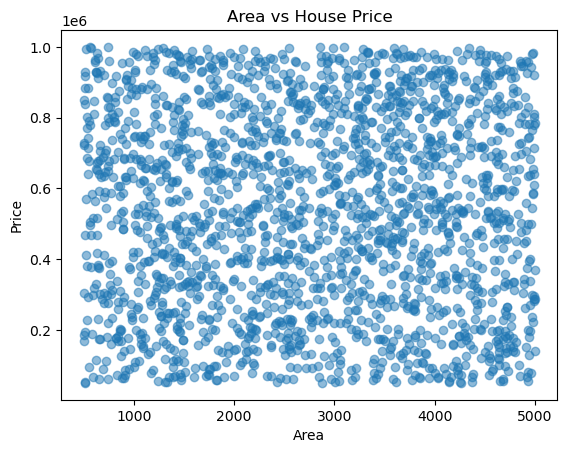

In [5]:
plt.scatter(df["Area"], df["Price"], alpha=0.5)
plt.xlabel("Area")
plt.ylabel("Price")
plt.title("Area vs House Price")
plt.show()

## Cell 4: Clean and select inputs
The uploaded file currently has no missing values, but `dropna()` safely handles missing rows. `Id` is an identifier, not a useful house feature. `Price` is the target. `get_dummies()` converts the three text columns into numeric indicator columns, so Linear Regression can use them.

In [6]:
df = df.dropna()
X = df.drop(columns=["Id", "Price"])
y = df["Price"]
X = pd.get_dummies(X, drop_first=True, dtype=int)

## Cell 5: Train-test split and model
With `test_size=0.2`, the model trains on 80% of the records and predicts the other 20%. `random_state=42` makes the split repeatable. `fit()` learns from training data, `predict()` estimates test prices.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

## Cell 6: Evaluate
Higher R² is generally better; lower MAE and RMSE are better. A negative R² means the model did worse on the test data than using the test set’s average actual price as a constant prediction.

In [8]:
print("R2 Score:", round(r2_score(y_test, y_pred), 3))
print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))
print("RMSE:", round(mean_squared_error(y_test, y_pred) ** 0.5, 2))

R2 Score: -0.007
MAE: 243241.98
RMSE: 279859.73


## Cell 7: Plot actual versus predicted prices
Each dot is a house in the test set. The dashed line indicates ideal predictions, where predicted price equals actual price.

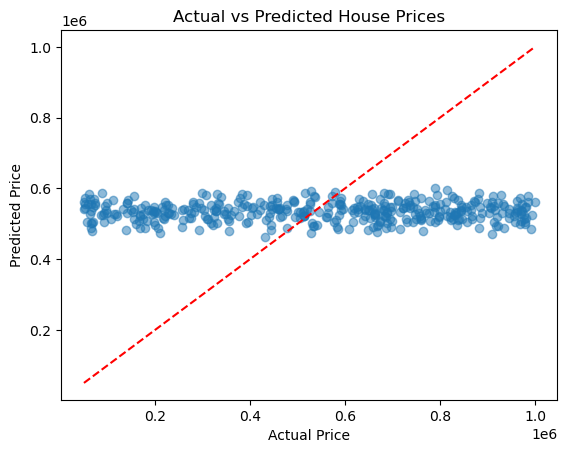

In [9]:
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")
plt.show()